In [26]:
import read_data
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, fbeta_score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

In [27]:
import importlib
import read_data

importlib.reload(read_data)

<module 'read_data' from 'c:\\Users\\utente\\Documents\\GitHub\\FYS-STK3155--Project3--UiO\\code\\read_data.py'>

In [28]:
X_events, y = read_data.ImportTrainingData()
X = read_data.aggregate(X_events)

In [29]:
X = read_data.aggregate(X_events)

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y # stratify to split successes evenly, since we have so few
)

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Solution to values too large, given by Chat:

cov_cols = [
    col for col in X_train.columns
    if "position_covariance_det" in col
]

for data in [X_train, X_test]:
    data[cov_cols] = np.sign(data[cov_cols]) * np.log1p(
        np.abs(data[cov_cols])
    )

In [31]:
limit = np.finfo(np.float32).max

for name, data in [("train", X_train), ("test", X_test)]: # Given by Chat, some values were too big
    numeric = data.select_dtypes(include=np.number)

    print(f"\n{name}:")
    print("Infinite values:", np.isinf(numeric).sum().sum())

    large = numeric.columns[(numeric.abs() > limit).any()]
    print("Columns with excessively large values:", large.tolist())


train:
Infinite values: 0
Columns with excessively large values: []

test:
Infinite values: 0
Columns with excessively large values: []


In [32]:
model = XGBClassifier()
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [33]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)


In [34]:
print(sum(y_prob))
print(sum(y_pred))
print(sum(y_test))

4.5534325
2
13


In [35]:
read_data.evaluate(model, X_test, y_test)

0.07796367891132833

In [36]:
for X, y in [(X_train, y_train), (X_test, y_test)]:
    prob = model.predict_proba(X)[:, 1]
    pred = model.predict(X)

    mse = mean_squared_error(y, prob)
    f2 = fbeta_score(y, pred, beta=2, zero_division=0)

    print(f"MSE: {mse:.4f}, F2: {f2:.4f}, Loss: {mse/f2 if f2 else float('inf'):.4f}")

MSE: 0.0000, F2: 1.0000, Loss: 0.0000
MSE: 0.0072, F2: 0.0926, Loss: 0.0780


In [37]:
trees = model.get_booster().trees_to_dataframe()
print(trees.groupby("Tree")["Node"].count().describe())

count       100.0
mean        11.06
std      8.955355
min           3.0
25%           5.0
50%           7.0
75%          13.0
max          43.0
Name: Node, dtype: Float64


Testing different models

In [38]:
loss_per_depth = []

for d in range(2, 20):
    model_d = XGBClassifier(max_depth=d, n_estimators=100)
    model_d.fit(X_train, y_train)

    print(f"Depth {d}: ", end="")
    loss_per_depth.append(read_data.evaluate(model_d, X_test, y_test))
print(loss_per_depth)


Depth 2: Depth 3: Depth 4: Depth 5: Depth 6: Depth 7: Depth 8: Depth 9: Depth 10: Depth 11: Depth 12: Depth 13: Depth 14: Depth 15: Depth 16: Depth 17: Depth 18: Depth 19: [0.08413768485188484, inf, 0.03707467205822468, 0.07999320924282075, 0.07796367891132833, 0.08149969484657049, inf, inf, inf, inf, inf, inf, inf, inf, inf, inf, inf, inf]


Best depth 4

In [39]:
trees = model.get_booster().trees_to_dataframe()
print(trees.groupby("Tree")["Node"].count().describe())

count       100.0
mean        11.06
std      8.955355
min           3.0
25%           5.0
50%           7.0
75%          13.0
max          43.0
Name: Node, dtype: Float64


Big flase-negative problem still, so we scale positive weight

In [40]:
loss_per_weight = []

for w in range(1, 100):
    model_w = XGBClassifier(max_depth=4, n_estimators=100, scale_pos_weight=w)
    model_w.fit(X_train, y_train)

    print(f"Weight {w}: ", end="")
    loss_per_weight.append(read_data.evaluate(model_w, X_test, y_test))
print(loss_per_weight)

Weight 1: Weight 2: Weight 3: Weight 4: Weight 5: Weight 6: Weight 7: Weight 8: Weight 9: Weight 10: Weight 11: Weight 12: Weight 13: Weight 14: Weight 15: Weight 16: Weight 17: Weight 18: Weight 19: Weight 20: Weight 21: Weight 22: Weight 23: Weight 24: Weight 25: Weight 26: Weight 27: Weight 28: Weight 29: Weight 30: Weight 31: Weight 32: Weight 33: Weight 34: Weight 35: Weight 36: Weight 37: Weight 38: Weight 39: Weight 40: Weight 41: Weight 42: Weight 43: Weight 44: Weight 45: Weight 46: Weight 47: Weight 48: Weight 49: Weight 50: Weight 51: Weight 52: Weight 53: Weight 54: Weight 55: Weight 56: Weight 57: Weight 58: Weight 59: Weight 60: Weight 61: Weight 62: Weight 63: Weight 64: Weight 65: Weight 66: Weight 67: Weight 68: Weight 69: Weight 70: Weight 71: Weight 72: Weight 73: Weight 74: Weight 75: Weight 76: Weight 77: Weight 78: Weight 79: Weight 80: Weight 81: Weight 82: Weight 83: Weight 84: Weight 85: Weight 86: Weight 87: Weight 88: Weight 89: Weight 90: Weight 91: Weight 9

In [41]:
print(min(loss_per_weight))
loss_per_weight.index(min(loss_per_weight))

0.023338037263602018


79

In [42]:
loss_per_tree = []

for t in range(10, 1000, 10):
    model_t = XGBClassifier(max_depth=4, n_estimators=t, scale_pos_weight=25)
    model_t.fit(X_train, y_train)

    print(f"Trees {t}: ", end="")
    loss_per_tree.append(read_data.evaluate(model_t, X_test, y_test))
print(loss_per_tree)

Trees 10: Trees 20: Trees 30: Trees 40: Trees 50: Trees 60: Trees 70: Trees 80: Trees 90: Trees 100: Trees 110: Trees 120: Trees 130: Trees 140: Trees 150: Trees 160: Trees 170: Trees 180: Trees 190: Trees 200: Trees 210: Trees 220: Trees 230: Trees 240: Trees 250: Trees 260: Trees 270: Trees 280: Trees 290: Trees 300: Trees 310: Trees 320: Trees 330: Trees 340: Trees 350: Trees 360: Trees 370: Trees 380: Trees 390: Trees 400: Trees 410: Trees 420: Trees 430: Trees 440: Trees 450: Trees 460: Trees 470: Trees 480: Trees 490: Trees 500: Trees 510: Trees 520: Trees 530: Trees 540: Trees 550: Trees 560: Trees 570: Trees 580: Trees 590: Trees 600: Trees 610: Trees 620: Trees 630: Trees 640: 

KeyboardInterrupt: 

In [43]:
print(min(loss_per_tree))
print(loss_per_tree.index(min(loss_per_tree)))

0.026962384674698116
5


index 5 gives 60 trees

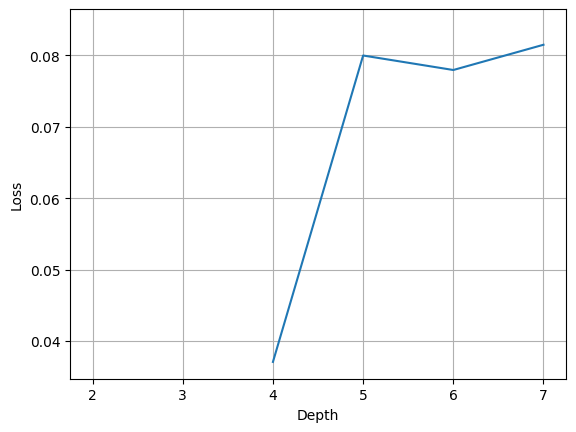

In [44]:
plt.plot(range(2, 20), loss_per_depth)
plt.xlabel("Depth")
plt.ylabel("Loss")
plt.grid()
plt.show() # ealy values not shown as depth three gives infinate loss, which breaks continuity

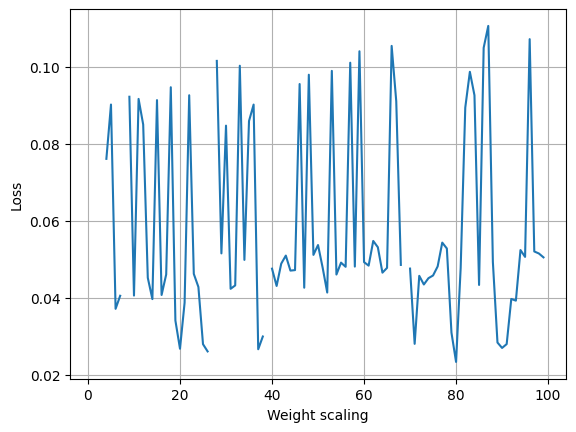

In [ ]:
plt.plot(range(1,100), loss_per_weight)
plt.xlabel("Weight scaling")
plt.ylabel("Loss")
plt.grid()
plt.show()

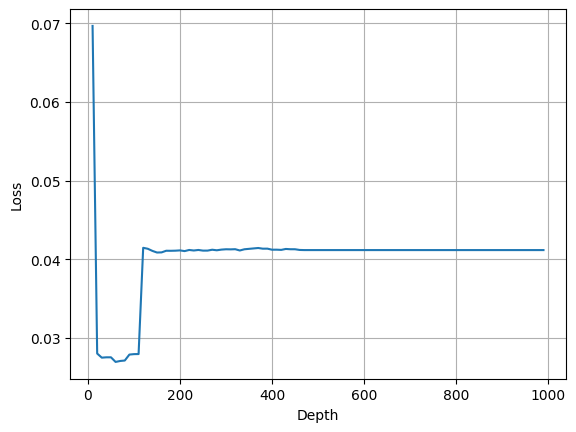

In [ ]:
plt.plot(range(10,1000,10), loss_per_tree)
plt.xlabel("Depth")
plt.ylabel("Loss")
plt.grid()
plt.show() # ealy values not shown as depth three gives infinate loss, which breaks continuity

In [45]:
for seed in [1, 10, 42, 100, 200]:
    model = XGBClassifier(
        max_depth=4,
        n_estimators=60,
        scale_pos_weight=79,
        random_state=seed
    )

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=seed,
        stratify=y # stratify to split successes evenly, since we have so few
    )

    X_train = X_train.replace([np.inf, -np.inf], np.nan)
    X_test = X_test.replace([np.inf, -np.inf], np.nan)

    model.fit(X_train, y_train)
    print(seed, read_data.evaluate(model, X_test, y_test))

1 inf
10 inf
42 0.015663719084113837
100 inf
200 inf


In [ ]:
weights = range(1,150)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

mses_list = []
f2s_zeros = []

for weight in weights:
    mses, f2s, recalls = [], [], []

    for train_idx, val_idx in cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = np.array(y)[train_idx], np.array(y)[val_idx]

        X_train = X_train.replace([np.inf, -np.inf], np.nan)
        X_val = X_val.replace([np.inf, -np.inf], np.nan)

        model = XGBClassifier(
            max_depth=4,
            n_estimators=60,
            scale_pos_weight=weight,
            random_state=42
        )

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_val)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        mses.append(mean_squared_error(y_val, probabilities))
        f2s.append(fbeta_score(y_val, predictions, beta=2, zero_division=0))


    print(
        f"Weight: {weight:3} | "
        f"MSE: {np.mean(mses):.4f} | "
        f"F2: {np.mean(f2s):.4f} ± {np.std(f2s):.4f} | "
        f"Zero F2: {sum(f == 0 for f in f2s)}/5"
    )
    mses_list.append(mses)
    f2s_zeros.append(sum(f == 0 for f in f2s))

    #RUN NEXT TIMEb

Weight:   1 | MSE: 0.0071 | F2: 0.0000 ± 0.0000 | Zero F2: 5/5
Weight:   2 | MSE: 0.0074 | F2: 0.1111 ± 0.2222 | Zero F2: 4/5
Weight:   3 | MSE: 0.0077 | F2: 0.1111 ± 0.2222 | Zero F2: 4/5


KeyboardInterrupt: 

ValueError: x and y must have same first dimension, but have shapes (149,) and (5,)

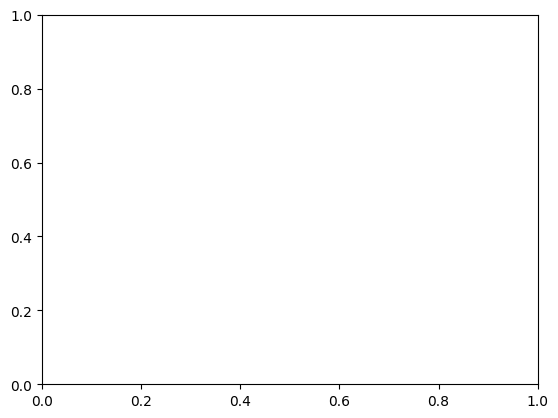

In [50]:
plt.plot(weights, mses)
plt.xlabel("Weight scaling")
plt.ylabel("MSE")
plt.grid()
plt.show() # ealy values not shown as depth three gives infinate loss, which breaks continuity

In [ ]:
plt.plot(weights, sum(f == 0 for f in f2s))
plt.xlabel("Weight scaling")
plt.ylabel("amount of F2 = 0æ")
plt.grid()
plt.show() # ealy values not shown as depth three gives infinate loss, which breaks continuity